# Guías 2 y 3 adaptadas: fracturas

Clasificador binario denso inspirado en las guías: entrada aplanada de 64×64, dos capas ocultas ReLU (256 y 128), dos logits, entropía cruzada y SGD. Las etiquetas usan nombres reales de carpetas y orden ImageFolder, que se imprime. Se conserva test oficial sin uso en entrenamiento.


In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd().resolve().parents[1] if Path.cwd().name == "fracturas" else Path.cwd().resolve()
sys.path.insert(0,str(ROOT/"src"))
from fracture_experiment import *
seed_everything()
train_loader,val_loader,test_loader,classes=data_loaders(image_size=64,batch_size=64)
print("clases:",classes,"tamaños:",len(train_loader.dataset),len(val_loader.dataset),len(test_loader.dataset))
x,y=next(iter(train_loader)); print("batch:",x.shape,y.shape,"rango:",(x.min().item(),x.max().item()))
assert x.shape[1:]==(1,64,64) and len(classes)==2

clases: ['fractured', 'not fractured'] tamaños: 9246 829 506
batch: torch.Size([64, 1, 64, 64]) torch.Size([64]) rango: (-1.0, 0.9843137264251709)


## Guía 2: red y pasada hacia adelante
La última capa entrega dos logits, sin softmax, para `CrossEntropyLoss`. Se conserva explícitamente la dimensión de batch incluso al probar una sola imagen: la entrada individual se expresa como `(1, 1, 64, 64)` y la salida como `(1, 2)`.

In [2]:
device="cuda" if torch.cuda.is_available() else "cpu"
model=network().to(device)
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(model.parameters(),lr=0.003)
logits=model(x.to(device)); print("salida:",logits.shape,"pérdida:",criterion(logits,y.to(device)).item())
assert logits.shape==(len(y),2)
single_logits=model(x[:1].to(device)); print("una imagen:",single_logits.shape)
assert single_logits.shape==(1,2)

salida: torch.Size([64, 2]) pérdida: 0.691235363483429
una imagen: torch.Size([1, 2])


## Guía 3: entrenamiento y validación
El test oficial no interviene en ajustes. La arquitectura permanece densa, como en las guías originales.

In [3]:
history={"train_loss":[],"train_accuracy":[],"val_loss":[],"val_accuracy":[]}
for e in range(5):
    tr=epoch(model,train_loader,criterion,optimizer,device); va=epoch(model,val_loader,criterion,None,device)
    for k,v in zip(history,[tr[0],tr[1],va[0],va[1]]): history[k].append(v)
    print(f"época {e+1}: train loss={tr[0]:.4f}, acc={tr[1]:.4f}; val loss={va[0]:.4f}, acc={va[1]:.4f}")
save_history(history,"fracturas_entrega1")

c:\Users\Cazatrolas\Documents\Fundamentos-Calculo-Numerico\.venv\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


época 1: train loss=0.6839, acc=0.5971; val loss=0.6706, acc=0.6936
época 2: train loss=0.6636, acc=0.6590; val loss=0.6535, acc=0.6852
época 3: train loss=0.6429, acc=0.6812; val loss=0.6361, acc=0.6912
época 4: train loss=0.6196, acc=0.6913; val loss=0.6091, acc=0.7021
época 5: train loss=0.5954, acc=0.7034; val loss=0.6108, acc=0.6779


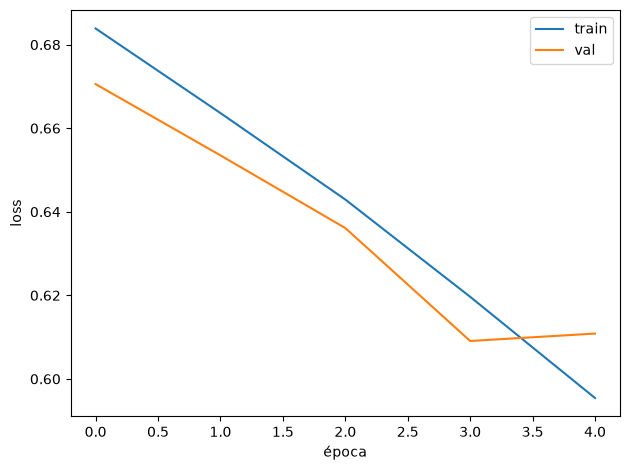

In [4]:
import matplotlib.pyplot as plt
RESULTS.joinpath("figures").mkdir(parents=True,exist_ok=True)
plt.plot(history["train_loss"],label="train"); plt.plot(history["val_loss"],label="val"); plt.xlabel("época"); plt.ylabel("loss"); plt.legend(); plt.tight_layout(); plt.savefig(RESULTS/"figures"/"fracturas_entrega1_loss.png",dpi=150); plt.show()

## Estado de la ejecución
La exportación ejecutada registra cinco épocas de entrenamiento y validación. El conjunto test permanece reservado.